# 3. Zep / Graphiti

**The idea in one screen.** Zep stores what a user said as a *graph*. The things
mentioned (people, places, a diet, an allergy) are **nodes**. Each fact is an
**edge** between two nodes, and every edge carries the dates between which it was
true. When the user changes their mind, the old edge is not deleted and not
overwritten: it gets an end date.

Every message goes through the same four steps, and each step makes one or
more model calls.

![Zep and Graphiti's architecture, with the running example. Writing: every message goes through four LLM steps (find entities, match them to stored ones, extract facts, compare with stored facts), 36 calls for ten messages. Memory: a graph of entities whose edges are facts with dates; the vegetarian edge was closed on 20 June 2026 and a pescatarian edge opened. Reading: a hybrid search with a 0.6 similarity floor returned nine facts, including the closed one; the pescatarian fact, Jonas's coeliac disease and Kreuzberg fell below the floor, so the answer missed the diet, gluten and the area.](../docs/figures/architecture/graphiti.svg)

Reading is a search over the facts, by wording and by meaning, with the dates
attached to each result so the model can tell a current fact from a past one.

This notebook walks through those steps on a short conversation in which the
user changes their diet, and tries to answer four questions:

1. **Writing.** What goes into the graph, and what is silently left out?
2. **Revising.** What happens to the old fact when a new one contradicts it?
3. **The graph.** What does it give you that a table of dated facts would
   not?
4. **Cost.** What does it cost in model calls?

Reading, the remaining stage every notebook in this series looks at, is
section 4.

## What is run here

**Zep** is the hosted product. **Graphiti** is the open-source engine under it
([getzep/graphiti](https://github.com/getzep/graphiti), Apache-2.0), described
in the [Zep paper](https://arxiv.org/abs/2501.13956).

This notebook is a **simplified re-implementation**, written so that every
step can be read. It does not call `graphiti.add_episode()`. Instead:

- The **prompts are Graphiti's own**, imported from the `graphiti-core`
  package, together with its thresholds.
- The **control flow around them is ours**: about 150 lines of plain Python
  that follow Graphiti's `add_episode` step by step.
- The **graph is kept in Python objects**. There is no graph database.

Left out: entity summaries, structured attributes, communities, and the
cross-encoder reranker. None of them changes what happens to a fact.
The numbers below are one small model's behaviour inside Graphiti's prompts,
not the behaviour of Zep's hosted service.

## Setup

The models are set in [`config.py`](config.py), which also reads
`GEMINI_API_KEY` from the `.env` at the top of the repository.

In [1]:
import json
import math
import re
import textwrap
from collections import Counter
from dataclasses import dataclass, field
from datetime import datetime, timezone

import graphviz
import numpy as np
import pandas as pd
from IPython.display import SVG, display
from pydantic import BaseModel

from config import CHAT_MODEL, EMBED_MODEL, embed, generate

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)


def table(frame):
    """A table with text on the left and numbers on the right, each header over its column."""
    numbers = frame.select_dtypes("number").columns
    return (frame.style.hide(axis="index").format(precision=3, thousands=",", na_rep="")
            .set_table_styles([{"selector": "th", "props": "text-align: left;"},
                               {"selector": "td", "props": "text-align: left; white-space: pre-wrap;"},
                               {"selector": "caption", "props": "text-align: left; font-weight: bold;"}])
            .set_table_styles({column: [{"selector": "", "props": "text-align: right;"}] for column in numbers},
                              overwrite=False))


print(f"chat model: {CHAT_MODEL}   embedding model: {EMBED_MODEL}")

chat model: gemini-3.1-flash-lite   embedding model: gemini-embedding-001


Two helpers make the model calls. Each one writes a line to a log, so that at
the end we can count what every step cost.

In [2]:
CALLS = []    # one entry per LLM call
EMBEDS = []   # one entry per embedding call


def llm(step, messages, schema):
    """Send one of Graphiti's prompts to the model and return the reply as a dict."""
    system, prompt = messages[0].content, messages[1].content
    reply = generate(prompt, system=system, schema=schema)
    answer = json.loads(reply.text)
    CALLS.append({
        "step": step, "prompt": prompt, "reply": answer,
        "tokens in": reply.usage_metadata.prompt_token_count,
        "tokens out": reply.usage_metadata.candidates_token_count,
    })
    return answer


def embed_texts(texts, why):
    """Turn texts into unit-length vectors, so a dot product is a cosine similarity."""
    vectors = np.array(embed(texts))
    EMBEDS.append({"why": why, "texts": len(texts)})
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

## The conversation

The conversation from [notebook 0](00-introduction.ipynb), repeated here so
that this notebook runs on its own. Two sessions four months apart, then a question in a third. Session 2 reverses
something from session 1 (the diet) and adds two people.

In [3]:
USER = "Anton"

SESSION_1 = [  # 14 March 2026
    ("user", "I'm planning a dinner for my sister's visit to Berlin next week. "
             "Worth saying up front: I've been strictly vegetarian for eight years, "
             "and I have a severe peanut allergy — anaphylactic, not a preference."),
    ("assistant", "Understood — no meat, and peanuts are a hard exclusion. Any cuisine you lean towards?"),
    ("user", "Indian, usually. Paneer dishes especially. And I'd rather not spend more "
             "than about 40 euros a head."),
]

SESSION_2 = [  # 20 July 2026, four months later
    ("user", "Small update on the food thing — I started eating fish about a month ago. "
             "So I'm pescatarian now, not vegetarian. Still no meat, and the peanut "
             "situation obviously hasn't changed."),
    ("assistant", "Noted, fish is in. Anything else shifted?"),
    ("user", "I moved to Kreuzberg in May, so anything walkable from there is a plus."),
    ("assistant", "Kreuzberg, noted. Anything else for next time?"),
    ("user", "Yes — my sister Lena is coming back in the autumn, and she's bringing her partner, Jonas."),
    ("assistant", "Lovely. Anything I should know about what they eat?"),
    ("user", "Lena can't eat shellfish, and Jonas is coeliac."),
]

QUESTION = (  # a new session in September, with no transcript
    "My sister and her partner are in town tonight. Book the three of us somewhere "
    "for dinner — you know what we can and can't eat."
)

SESSION_DATES = {
    "s1": datetime(2026, 3, 14, 19, 0, tzinfo=timezone.utc),
    "s2": datetime(2026, 7, 20, 19, 0, tzinfo=timezone.utc),
}
TODAY = datetime(2026, 9, 1, tzinfo=timezone.utc)


def as_messages(key, session):
    """Graphiti takes one message at a time, with the speaker's name in the text."""
    speaker = {"user": USER, "assistant": "Assistant"}
    return [
        {"label": f"{key}.{i + 1}", "role": role, "content": f"{speaker[role]}: {text}",
         "time": SESSION_DATES[key].replace(minute=i)}
        for i, (role, text) in enumerate(session)
    ]


MESSAGES = as_messages("s1", SESSION_1) + as_messages("s2", SESSION_2)


def show_session(caption, turns):
    """One session as a table, under its date."""
    return table(pd.DataFrame(turns)).set_caption(caption)


display(show_session("Session 1 · 14 March 2026", [{key: m[key] for key in ("label", "time", "content")} for m in MESSAGES if m["label"].startswith("s1.")]))
display(show_session("Session 2 · 20 July 2026, four months later", [{key: m[key] for key in ("label", "time", "content")} for m in MESSAGES if m["label"].startswith("s2.")]))
display(show_session("Session 3 · 1 September 2026, with no transcript", [{"content": f"{USER}: {QUESTION}"}]))

label,time,content
s1.1,2026-03-14 19:00:00+00:00,"Anton: I'm planning a dinner for my sister's visit to Berlin next week. Worth saying up front: I've been strictly vegetarian for eight years, and I have a severe peanut allergy — anaphylactic, not a preference."
s1.2,2026-03-14 19:01:00+00:00,"Assistant: Understood — no meat, and peanuts are a hard exclusion. Any cuisine you lean towards?"
s1.3,2026-03-14 19:02:00+00:00,"Anton: Indian, usually. Paneer dishes especially. And I'd rather not spend more than about 40 euros a head."


label,time,content
s2.1,2026-07-20 19:00:00+00:00,"Anton: Small update on the food thing — I started eating fish about a month ago. So I'm pescatarian now, not vegetarian. Still no meat, and the peanut situation obviously hasn't changed."
s2.2,2026-07-20 19:01:00+00:00,"Assistant: Noted, fish is in. Anything else shifted?"
s2.3,2026-07-20 19:02:00+00:00,"Anton: I moved to Kreuzberg in May, so anything walkable from there is a plus."
s2.4,2026-07-20 19:03:00+00:00,"Assistant: Kreuzberg, noted. Anything else for next time?"
s2.5,2026-07-20 19:04:00+00:00,"Anton: Yes — my sister Lena is coming back in the autumn, and she's bringing her partner, Jonas."
s2.6,2026-07-20 19:05:00+00:00,Assistant: Lovely. Anything I should know about what they eat?
s2.7,2026-07-20 19:06:00+00:00,"Anton: Lena can't eat shellfish, and Jonas is coeliac."


content
Anton: My sister and her partner are in town tonight. Book the three of us somewhere for dinner — you know what we can and can't eat.


A correct answer to the question needs six things from those two sessions:
pescatarian (no longer vegetarian), no peanuts, no shellfish for Lena, no
gluten for Jonas, a liking for Indian food, and somewhere near Kreuzberg.

## The graph

Two kinds of object. An **entity** is a node: a name and a type. A **fact** is
an edge from one entity to another: a relation name, a sentence, and four dates
that are explained further down.

In [4]:
@dataclass(eq=False)
class Entity:
    name: str
    kind: str = "Entity"
    vector: np.ndarray = None       # embedding of the name


@dataclass(eq=False)
class Fact:
    source: str                     # name of the entity the edge starts at
    target: str                     # name of the entity it points to
    relation: str                   # e.g. LIVES_IN
    text: str                       # the fact as a sentence
    valid_at: datetime = None       # when it became true in the world
    invalid_at: datetime = None     # when it stopped being true in the world
    created_at: datetime = None     # when the graph learned it
    expired_at: datetime = None     # when the graph stopped believing it
    said_in: str = ""               # label of the message it came from
    vector: np.ndarray = None       # embedding of the sentence


@dataclass
class Graph:
    entities: dict = field(default_factory=dict)    # name -> Entity
    facts: list = field(default_factory=list)
    messages: list = field(default_factory=list)    # messages ingested so far

And a function to draw it. Entities are boxes, coloured by type. Facts are
arrows labelled with their relation. A fact that has been given an end date is
drawn dashed and grey.

In [5]:
KIND_COLOURS = {"Person": "#dbe9f6", "Place": "#e3f1e3", "Preference": "#fff1c9",
                "HealthCondition": "#f9dcdc", "Entity": "#eeeeee"}


def day(moment):
    return moment.strftime("%Y-%m-%d") if moment else "—"


def two_lines(text, separator, longest=14):
    """Break a long label in two at the separator nearest its middle."""
    places = [i for i, c in enumerate(text) if c == separator]
    if len(text) <= longest or not places:
        return text
    middle = min(places, key=lambda i: abs(i - len(text) / 2))
    return text[:middle + 1].rstrip() + "\n" + text[middle + 1:]


def draw(graph, highlight=()):
    """Draw the graph. `highlight` is a list of facts to draw in bold blue."""
    picture = graphviz.Digraph(
        # `size` is in inches: the picture is scaled down if it would be wider than 8.4
        graph_attr={"rankdir": "LR", "bgcolor": "white", "nodesep": "0.2", "ranksep": "0.45",
                    "size": "8.4,30"},
        node_attr={"shape": "box", "style": "rounded,filled", "fontname": "Helvetica", "fontsize": "11"},
        edge_attr={"fontname": "Helvetica", "fontsize": "9"},
    )
    for entity in graph.entities.values():
        picture.node(entity.name, f"{two_lines(entity.name, ' ')}\n({entity.kind})",
                     fillcolor=KIND_COLOURS.get(entity.kind, "#eeeeee"))
    for fact in graph.facts:
        label = two_lines(fact.relation, "_")
        style = {}
        if fact.invalid_at:
            label += f"\nuntil {day(fact.invalid_at)}"
            style = {"style": "dashed", "color": "#999999", "fontcolor": "#999999"}
        if fact in highlight:
            style = {"color": "#1f6fb2", "fontcolor": "#1f6fb2", "penwidth": "2.5"}
        picture.edge(fact.source, fact.target, label=label, **style)
    return picture


def facts_table(facts):
    return pd.DataFrame([
        {"from": f.source, "relation": f.relation, "to": f.target, "fact": f.text,
         "valid_at": day(f.valid_at), "invalid_at": day(f.invalid_at),
         "created_at": day(f.created_at), "expired_at": day(f.expired_at)}
        for f in facts
    ])


def show_prompt(prompt, width=110):
    """Print a prompt with long lines wrapped and the worked examples left out."""
    prompt = re.sub(r"<EXAMPLE>.*?</EXAMPLE>\n*", "", prompt, flags=re.S)
    for line in prompt.strip().splitlines():
        print(textwrap.fill(line, width, subsequent_indent="    ") if line.strip() else "")

## 1. One message, step by step

The first message of session 1 is the one that states the diet and the allergy.

### Step 1: find the entities

The model is asked to list the things the message mentions. The prompt is
Graphiti's `extract_nodes.extract_message`.

In [6]:
from graphiti_core.prompts import dedupe_edges, dedupe_nodes, extract_edges, extract_nodes
from graphiti_core.search.search_utils import DEFAULT_MIN_SCORE, MAX_SEARCH_DEPTH, RELEVANT_SCHEMA_LIMIT
from graphiti_core.utils.maintenance.node_operations import (
    NODE_DEDUP_CANDIDATE_LIMIT, NODE_DEDUP_COSINE_MIN_SCORE, _build_entity_types_context,
)


def previous_messages(graph):
    """What Graphiti passes along as context: the last few messages already ingested.

    The paper says the last four. The library passes up to ten.
    """
    return [{"content": m["content"], "timestamp": m["time"].isoformat()}
            for m in graph.messages[-RELEVANT_SCHEMA_LIMIT:]]


def find_entities(graph, message, entity_types=None):
    types = _build_entity_types_context(entity_types)   # the default type, plus any we define
    reply = llm("1. find entities", extract_nodes.extract_message({
        "episode_content": message["content"],
        "episode_timestamp": message["time"].isoformat(),
        "previous_episodes": previous_messages(graph),
        "entity_types": types,
        "custom_extraction_instructions": "",
        "source_description": "chat with a booking assistant",
    }), extract_nodes.ExtractedEntities)

    found = {}
    for item in reply["extracted_entities"]:
        name = item["name"].strip()
        if name and name not in found:
            found[name] = Entity(name, kind=types[item["entity_type_id"]]["entity_type_name"])
    return list(found.values())


graph = Graph()
first = MESSAGES[0]
found = find_entities(graph, first)
CALLS[-1]["message"] = "s1.1, default types"
table(pd.DataFrame([{"entity": e.name, "type": e.kind} for e in found]))

entity,type
Anton,Entity
Anton's sister,Entity
Berlin,Entity


Three entities: the speaker, the sister, the city. **The vegetarian diet and
the peanut allergy are not there.** Those are the two things this conversation
is about, and one of them is life-threatening.

This matters more here than it would in another system, because of how the
next step works: a fact can only be stored as an edge **between two entities**.
If nothing was created for "vegetarian" to point at, the sentence *"Anton is
vegetarian"* has nowhere to go, and it is dropped.

Why did the model leave them out? Because the prompt tells it to. Here are the
instructions it was given (the worked examples are left out for length):

In [7]:
show_prompt(CALLS[-1]["prompt"])

NEVER extract any of the following:
- Pronouns (you, me, I, he, she, they, we, us, it, them, him, her, this, that, those)
- Abstract concepts or feelings (joy, balance, growth, resilience, happiness, passion, motivation)
- Generic common nouns or bare object words (day, life, people, work, stuff, things, food, time,
  way, tickets, supplies, clothes, keys, gear)
- Generic media/content nouns unless uniquely identified in the node name itself (photo, pic, picture,
  image, video, post, story)
- Generic event/activity nouns unless uniquely identified in the node name itself (event, game, meeting,
  class, workshop, competition)
- Broad institutional nouns unless explicitly named or uniquely qualified (government, school, company,
  team, office)
- Ambiguous bare nouns whose meaning depends on sentence context rather than the node name itself
- Sentence fragments or clauses ("what you really care about", "results of that effort")
- Adjectives or descriptive phrases ("amazing", "something 

The prompt is written for a knowledge graph of named things. It asks for
entities that *"could have their own Wikipedia article or database entry"*,
forbids *"abstract concepts"*, and ends with *"when in doubt, do NOT extract"*.
A diet and an allergy are attributes of a person, not named things, so a model
that follows the instructions leaves them out. This is not a random failure:
the temperature is 0 and the result is the same on every run.

### Tuning: tell it which kinds of thing matter

Graphiti's answer to this is **custom entity types**. You describe the kinds of
node your application cares about, and the descriptions are put into the same
prompt under `<ENTITY TYPES>`. They are written as classes with a docstring,
exactly as they would be passed to `add_episode(entity_types=...)`.

In [8]:
class Person(BaseModel):
    """A specific person: the speaker, or someone they name or describe by their relation to a named person."""


class Place(BaseModel):
    """A named city, district, venue or address."""


class Preference(BaseModel):
    """Something a person likes, dislikes, chooses or avoids: a diet they follow, a cuisine or dish they favour, a budget they keep to."""


class HealthCondition(BaseModel):
    """An allergy, intolerance or medical condition that limits what a person can eat or do."""


ENTITY_TYPES = {"Person": Person, "Place": Place, "Preference": Preference,
                "HealthCondition": HealthCondition}

found = find_entities(graph, first, ENTITY_TYPES)
table(pd.DataFrame([{"entity": e.name, "type": e.kind} for e in found]))

entity,type
Anton,Person
Anton's sister,Person
Berlin,Place
vegetarian,Preference
peanut allergy,HealthCondition


Same message, same model, same prompt apart from the list of types, and now
the diet and the allergy are entities. **The rest of this notebook uses these
four types.** Without them there would be no diet fact in the graph, and
nothing for session 2 to contradict.

The lesson is that the entity step decides what the memory is able to hold.
Out of the box it is tuned for names; for personal preferences it has to be
told.

### Step 2: match them to entities already in the graph

The same person or thing will be mentioned again, often in different words
(*"my sister"*, then *"Lena"*). This step decides, for each entity just found,
whether it is new or one the graph already has.

- An exact name match is reused directly.
- Otherwise the stored entities whose names are close in meaning (cosine
  similarity of at least 0.6) are collected as candidates, and the model is
  asked whether any of them is the same thing (`dedupe_nodes.nodes`).
- With no candidates, the entity is new.

In [9]:
def match_entities(graph, message, found):
    """Return {name as found: name in the graph}, adding the new entities to the graph."""
    vectors = embed_texts([e.name for e in found], "entity names")
    stored = list(graph.entities.values())
    same_as, unsure, candidates = {}, [], []

    for entity, vector in zip(found, vectors):
        entity.vector = vector
        exact = [s for s in stored if s.name.lower() == entity.name.lower()]
        if exact:
            same_as[entity.name] = exact[0].name
            continue
        close = sorted(stored, key=lambda s: -float(s.vector @ vector))[:NODE_DEDUP_CANDIDATE_LIMIT]
        close = [s for s in close if float(s.vector @ vector) >= NODE_DEDUP_COSINE_MIN_SCORE]
        if close:
            unsure.append(entity)
            candidates += [s for s in close if s not in candidates]

    if unsure:
        reply = llm("2. match entities", dedupe_nodes.nodes({
            "extracted_nodes": [{"id": i, "name": e.name, "entity_type": [e.kind]}
                                for i, e in enumerate(unsure)],
            "existing_nodes": [{"candidate_id": i, "name": c.name, "entity_types": [c.kind]}
                               for i, c in enumerate(candidates)],
            "episode_content": message["content"],
            "previous_episodes": previous_messages(graph),
        }), dedupe_nodes.NodeResolutions)
        for item in reply["entity_resolutions"]:
            if 0 <= item["id"] < len(unsure) and 0 <= item["duplicate_candidate_id"] < len(candidates):
                same_as[unsure[item["id"]].name] = candidates[item["duplicate_candidate_id"]].name

    for entity in found:
        if entity.name not in same_as:           # nothing matched: it is a new entity
            graph.entities[entity.name] = entity
            same_as[entity.name] = entity.name
    return same_as


same_as = match_entities(graph, first, found)
same_as

{'Anton': 'Anton',
 "Anton's sister": "Anton's sister",
 'Berlin': 'Berlin',
 'vegetarian': 'vegetarian',
 'peanut allergy': 'peanut allergy'}

The graph was empty, so all five are new and no model call was needed. This
step becomes interesting in session 2.

### Step 3: extract the facts

Now the model gets the message again, together with the list of entities, and
is asked for facts **between two of them**, with dates where the message gives
any (`extract_edges.edge`). These are the parts of the prompt that change from
message to message:

In [10]:
def extract_facts(graph, message, found, same_as):
    reply = llm("3. extract facts", extract_edges.edge({
        "episode_content": message["content"],
        "nodes": [{"name": e.name, "entity_types": [e.kind]} for e in found],
        "previous_episodes": previous_messages(graph),
        "reference_time": message["time"],
        "edge_types": [],
        "custom_extraction_instructions": "",
    }), extract_edges.ExtractedEdges)

    facts = []
    for item in reply["edges"]:
        source = same_as.get(item["source_entity_name"])
        target = same_as.get(item["target_entity_name"])
        if not source or not target or source == target:
            continue                              # both ends must be known, distinct entities
        facts.append(Fact(source, target, item["relation_type"], item["fact"],
                          valid_at=parse_date(item.get("valid_at")),
                          invalid_at=parse_date(item.get("invalid_at")),
                          created_at=message["time"], said_in=message["label"]))
    return facts


def parse_date(text):
    if not text:
        return None
    try:
        moment = datetime.fromisoformat(text.replace("Z", "+00:00"))
    except ValueError:
        return None
    return moment if moment.tzinfo else moment.replace(tzinfo=timezone.utc)


new_facts = extract_facts(graph, first, found, same_as)

prompt = CALLS[-1]["prompt"]
print(prompt[prompt.index("<CURRENT_MESSAGE>"):prompt.index("# TASK")].strip())

<CURRENT_MESSAGE>
Anton: I'm planning a dinner for my sister's visit to Berlin next week. Worth saying up front: I've been strictly vegetarian for eight years, and I have a severe peanut allergy — anaphylactic, not a preference.
</CURRENT_MESSAGE>

<ENTITIES>
[{"name": "Anton", "entity_types": ["Person"]}, {"name": "Anton's sister", "entity_types": ["Person"]}, {"name": "Berlin", "entity_types": ["Place"]}, {"name": "vegetarian", "entity_types": ["Preference"]}, {"name": "peanut allergy", "entity_types": ["HealthCondition"]}]
</ENTITIES>

<REFERENCE_TIME>
2026-03-14 19:00:00+00:00  # ISO 8601 (UTC); used to resolve relative time mentions
</REFERENCE_TIME>


And the reply, as the model returned it:

In [11]:
table(pd.DataFrame(CALLS[-1]["reply"]["edges"]).reindex(
    columns=["source_entity_name", "relation_type", "target_entity_name", "fact", "valid_at", "invalid_at"]
).fillna(""))

source_entity_name,relation_type,target_entity_name,fact,valid_at,invalid_at
Anton,HAS_SIBLING,Anton's sister,Anton has a sister who is visiting Berlin.,2026-03-14T19:00:00Z,
Anton,HAS_DIETARY_PREFERENCE,vegetarian,Anton has been strictly vegetarian for eight years.,2018-03-14T19:00:00Z,
Anton,HAS_HEALTH_CONDITION,peanut allergy,Anton has a severe anaphylactic peanut allergy.,2026-03-14T19:00:00Z,


Each row is one edge. Notice two things.

**The fact is a full sentence, with names instead of pronouns.** The prompt
asks for that. It means each fact can be read, embedded and searched on its
own, without the graph around it. Keep this in mind for section 5.

**The model worked out the dates.** *"Vegetarian for eight years"*, said on 14
March 2026, became `valid_at = 2018-03-14`. The message's own timestamp is
passed in as `REFERENCE_TIME` for exactly this.

### Step 4: compare each new fact with what is already stored

Before a fact is added, Graphiti looks for stored facts it might repeat or
contradict. It collects two lists:

- facts between **the same two entities** (possible duplicates), and
- the top 10 facts from a **search of the whole graph** for the new fact's
  sentence (possible contradictions).

If both lists are empty the fact is simply added. Otherwise the model is shown
the lists and asked which stored facts the new one duplicates and which it
contradicts (`dedupe_edges.resolve_edge`).

The search is the same one used for reading memory later, so it is defined
here. It ranks facts two ways and merges the rankings:

- **by wording**: BM25, a keyword score. Graphiti gets this from the graph
  database's full-text index; here it is 15 lines of Python.
- **by meaning**: cosine similarity between embeddings, keeping only facts
  that score at least 0.6.

In [12]:
STOP_WORDS = set("a an the and or of to in on for with is are was were be been i my me you your we our us "
                 "it its that this what can t s do does did not no so at by from as have has had about".split())


def words(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP_WORDS]


def rank_by_wording(query, facts, k1=1.2, b=0.75):
    """BM25: facts that share rarer words with the query score higher."""
    documents = [words(f.text) for f in facts]
    if not documents:
        return []
    average_length = sum(len(d) for d in documents) / len(documents)
    in_how_many = Counter(w for d in documents for w in set(d))
    scores = []
    for d in documents:
        counts = Counter(d)
        score = 0.0
        for w in set(words(query)) & set(d):
            rarity = math.log(1 + (len(documents) - in_how_many[w] + 0.5) / (in_how_many[w] + 0.5))
            score += rarity * counts[w] * (k1 + 1) / (counts[w] + k1 * (1 - b + b * len(d) / average_length))
        scores.append(score)
    order = sorted(range(len(facts)), key=lambda i: -scores[i])
    return [facts[i] for i in order if scores[i] > 0]


def rank_by_meaning(query_vector, facts, floor=DEFAULT_MIN_SCORE):
    order = sorted(facts, key=lambda f: -float(f.vector @ query_vector))
    return [f for f in order if float(f.vector @ query_vector) >= floor]


def merge_rankings(*rankings):
    """Reciprocal rank fusion: a fact scores 1/position in each ranking it appears in."""
    score, by_id = Counter(), {}
    for ranking in rankings:
        for position, fact in enumerate(ranking, start=1):
            score[id(fact)] += 1 / position
            by_id[id(fact)] = fact
    return [by_id[i] for i, _ in score.most_common()]


def search(query_text, query_vector, facts, limit=10, floor=DEFAULT_MIN_SCORE):
    return merge_rankings(rank_by_wording(query_text, facts),
                          rank_by_meaning(query_vector, facts, floor))[:limit]

Then the comparison itself. The model only says *which* stored facts are
contradicted. What happens to them is decided by ordinary code, from the dates:
`close_contradicted` below is Graphiti's `resolve_edge_contradictions`, with
the same three rules.

3 facts added, 0 closed


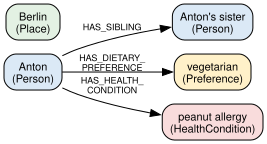

In [13]:
def close_contradicted(new, contradicted, now):
    """Give an end date to every stored fact the new one replaces. Returns the facts closed."""
    closed = []
    for old in contradicted:
        if old.invalid_at and new.valid_at and old.invalid_at <= new.valid_at:
            continue        # the old fact had already ended before the new one began
        if old.valid_at and new.invalid_at and new.invalid_at <= old.valid_at:
            continue        # the new fact had ended before the old one began
        if old.valid_at and new.valid_at and old.valid_at < new.valid_at:
            old.invalid_at = new.valid_at        # the old fact ends when the new one starts
            old.expired_at = old.expired_at or now
            closed.append(old)
    return closed


def compare_with_stored(graph, new, stored, message):
    """Add `new` to the graph unless it repeats a stored fact. Returns a record of what happened."""
    new.vector = embed_texts([new.text], "new fact")[0]
    same_pair = [f for f in stored if (f.source, f.target) == (new.source, new.target)]
    same_pair = search(new.text, new.vector, same_pair)
    candidates = [f for f in search(new.text, new.vector, stored) if f not in same_pair]
    record = {"new fact": new.text, "same pair": same_pair, "candidates": candidates,
              "duplicate of": None, "contradicts": [], "closed": []}

    if not same_pair and not candidates:
        graph.facts.append(new)
        return record

    shown = same_pair + candidates       # numbered 0, 1, 2 ... across both lists
    reply = llm("4. compare with stored facts", dedupe_edges.resolve_edge({
        "existing_edges": [{"idx": i, "fact": f.text} for i, f in enumerate(same_pair)],
        "edge_invalidation_candidates": [{"idx": len(same_pair) + i, "fact": f.text}
                                         for i, f in enumerate(candidates)],
        "new_edge": new.text,
    }), dedupe_edges.EdgeDuplicate)

    duplicates = [same_pair[i] for i in reply["duplicate_facts"] if 0 <= i < len(same_pair)]
    contradicted = [shown[i] for i in reply["contradicted_facts"] if 0 <= i < len(shown)]
    record["contradicts"] = contradicted

    if duplicates:                       # already known: keep the stored fact, drop the new one
        record["duplicate of"] = duplicates[0]
        kept = duplicates[0]
    else:
        graph.facts.append(new)
        kept = new

    record["closed"] = close_contradicted(kept, contradicted, now=message["time"])
    return record


# Every new fact is compared with the graph as it was before this message.
stored_before = list(graph.facts)
records = [compare_with_stored(graph, fact, stored_before, first) for fact in new_facts]
graph.messages.append(first)

print(f"{len(graph.facts)} facts added, {sum(len(r['closed']) for r in records)} closed")
draw(graph)

The graph was empty, so there was nothing to compare with and all the facts
went in. That is the whole pipeline for one message.

Two details of Graphiti are left out of this version. A fact that comes back
from step 3 without any date gets one more small model call to date it
(`extract_edges.extract_timestamps`), and a new fact that is older than the
fact it contradicts is itself closed on arrival. Neither would have fired in
this conversation: every fact came back dated, and nothing arrived out of
order.

### The four dates on a fact

Here are the stored facts with all four dates.

In [14]:
table(facts_table(graph.facts))

from,relation,to,fact,valid_at,invalid_at,created_at,expired_at
Anton,HAS_SIBLING,Anton's sister,Anton has a sister who is visiting Berlin.,2026-03-14,—,2026-03-14,—
Anton,HAS_DIETARY_PREFERENCE,vegetarian,Anton has been strictly vegetarian for eight years.,2018-03-14,—,2026-03-14,—
Anton,HAS_HEALTH_CONDITION,peanut allergy,Anton has a severe anaphylactic peanut allergy.,2026-03-14,—,2026-03-14,—


The dates answer two different questions.

| Date | Question it answers | Set by |
|---|---|---|
| `valid_at` | When did this become true **in the world**? | the model, from the message |
| `invalid_at` | When did it stop being true in the world? | code, when a newer fact contradicts it |
| `created_at` | When did **the graph** learn it? | code, at ingestion |
| `expired_at` | When did the graph stop believing it? | code, when the fact is closed |

The vegetarian fact shows why both pairs exist: it became true in 2018, but
the graph only learned it in March 2026. A system with one timestamp per row
has to pick one of the two.

In a real deployment `created_at` and `expired_at` are the wall-clock time of
ingestion. Here they are set to the time of the message, as if each session
were ingested on the day it happened.

## 2. The rest of session 1

The four steps, as one function.

In [15]:
def ingest(graph, message, entity_types=ENTITY_TYPES):
    """Run one message through the four steps. Returns a record of what each step did."""
    calls_before, embeds_before = len(CALLS), len(EMBEDS)

    found = find_entities(graph, message, entity_types)
    same_as = match_entities(graph, message, found) if found else {}
    new_facts = extract_facts(graph, message, found, same_as) if len(found) > 1 else []
    stored_before = list(graph.facts)
    records = [compare_with_stored(graph, fact, stored_before, message) for fact in new_facts]
    graph.messages.append(message)

    for entry in CALLS[calls_before:] + EMBEDS[embeds_before:]:
        entry["message"] = message["label"]      # so the cost table can group by message
    return {"message": message["label"], "found": found, "same_as": same_as, "records": records}


for entry in CALLS + EMBEDS:                     # the walkthrough above was message s1.1
    entry.setdefault("message", "s1.1")

LOG = {"s1.1": {"message": "s1.1", "found": found, "same_as": same_as, "records": records}}
for message in MESSAGES[1:3]:
    LOG[message["label"]] = ingest(graph, message)


def ingestion_summary(labels):
    rows = []
    for label in labels:
        entry = LOG[label]
        merged = {k: v for k, v in entry["same_as"].items() if k != v}
        rows.append({
            "message": label,
            "entities found": ", ".join(e.name for e in entry["found"]),
            "matched to a stored entity": ", ".join(f"{k} → {v}" for k, v in merged.items()) or "—",
            "facts added": sum(1 for r in entry["records"] if not r["duplicate of"]),
            "facts closed": sum(len(r["closed"]) for r in entry["records"]),
        })
    return pd.DataFrame(rows)


table(ingestion_summary(["s1.1", "s1.2", "s1.3"]))

message,entities found,matched to a stored entity,facts added,facts closed
s1.1,"Anton, Anton's sister, Berlin, vegetarian, peanut allergy",—,3,0
s1.2,Assistant,—,0,0
s1.3,"Anton, Indian cuisine, Paneer dishes, 40 euros a head budget",—,3,0


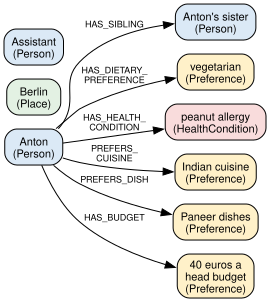

In [16]:
draw(graph)

In [17]:
table(facts_table(graph.facts)[["from", "relation", "to", "fact", "valid_at", "invalid_at"]])

from,relation,to,fact,valid_at,invalid_at
Anton,HAS_SIBLING,Anton's sister,Anton has a sister who is visiting Berlin.,2026-03-14,—
Anton,HAS_DIETARY_PREFERENCE,vegetarian,Anton has been strictly vegetarian for eight years.,2018-03-14,—
Anton,HAS_HEALTH_CONDITION,peanut allergy,Anton has a severe anaphylactic peanut allergy.,2026-03-14,—
Anton,PREFERS_CUISINE,Indian cuisine,Anton prefers Indian cuisine for his dinner plans.,2026-03-14,—
Anton,PREFERS_DISH,Paneer dishes,Anton specifically prefers paneer dishes when eating Indian cuisine.,2026-03-14,—
Anton,HAS_BUDGET,40 euros a head budget,Anton has a budget of 40 euros a head for his dinner.,2026-03-14,—


Six facts after session 1, and three things worth noticing.

- **Every edge starts at Anton.** A memory about one user is mostly a star
  around that user. This comes back in section 5.
- **The assistant's message went through the pipeline too** and cost two model
  calls. It produced one entity (*Assistant*) and no facts, because a fact
  needs two entities.
- **Berlin is a node with no edges.** The model put the visit into the sentence
  of the sister fact and did not connect the city to anything.

## 3. Session 2: the user changes their mind

Four months later. The first message of session 2 is the reversal:

In [18]:
reversal = MESSAGES[3]
print(reversal["content"])

Anton: Small update on the food thing — I started eating fish about a month ago. So I'm pescatarian now, not vegetarian. Still no meat, and the peanut situation obviously hasn't changed.


In [19]:
facts_before = list(graph.facts)
LOG["s2.1"] = ingest(graph, reversal)
table(ingestion_summary(["s2.1"]))

message,entities found,matched to a stored entity,facts added,facts closed
s2.1,"Anton, pescatarian diet, peanut allergy",—,1,1


Steps 1 to 3 ran as before. Step 4 is where the reversal is handled, so here
it is in full. For each new fact: the stored facts that were put in front of
the model, and what it answered.

In [20]:
def show_comparisons(entry):
    for record in entry["records"]:
        print(f"NEW FACT        {record['new fact']}")
        shown = record["same pair"] + record["candidates"]
        if not shown:
            print("  nothing stored to compare with: added\n")
            continue
        for i, fact in enumerate(shown):
            where = "same two entities" if i < len(record["same pair"]) else "found by search  "
            verdict = ("DUPLICATE" if fact is record["duplicate of"]
                       else "CONTRADICTED" if fact in record["contradicts"] else "")
            print(f"  [{i}] {where}  {fact.text}   {verdict}")
        for fact in record["closed"]:
            print(f"  -> closed: “{fact.text}” now ends {day(fact.invalid_at)}")
        print()


show_comparisons(LOG["s2.1"])

NEW FACT        Anton started following a pescatarian diet about a month ago.
  [0] found by search    Anton has been strictly vegetarian for eight years.   CONTRADICTED
  [1] found by search    Anton has a sister who is visiting Berlin.   
  [2] found by search    Anton prefers Indian cuisine for his dinner plans.   
  [3] found by search    Anton has a severe anaphylactic peanut allergy.   
  [4] found by search    Anton specifically prefers paneer dishes when eating Indian cuisine.   
  [5] found by search    Anton has a budget of 40 euros a head for his dinner.   
  -> closed: “Anton has been strictly vegetarian for eight years.” now ends 2026-06-20

NEW FACT        Anton has a severe peanut allergy.
  [0] same two entities  Anton has a severe anaphylactic peanut allergy.   DUPLICATE
  [1] found by search    Anton has been strictly vegetarian for eight years.   
  [2] found by search    Anton has a sister who is visiting Berlin.   
  [3] found by search    Anton prefers Indian cuis

The exact prompt for one of those comparisons, and the model's reply:

In [21]:
compare_calls = [c for c in CALLS if c["step"].startswith("4.") and c["message"] == "s2.1"]
compare_call = next((c for c in compare_calls if c["reply"]["contradicted_facts"]), compare_calls[0])
show_prompt(compare_call["prompt"])
print("\nREPLY", compare_call["reply"])

NEVER mark facts as duplicates if they have key differences, particularly around numeric values, dates, or key
    qualifiers.

IMPORTANT constraints:
- duplicate_facts: ONLY idx values from EXISTING FACTS (NEVER include FACT INVALIDATION CANDIDATES)
- contradicted_facts: idx values from EITHER list (EXISTING FACTS or FACT INVALIDATION CANDIDATES)
- The idx values are continuous across both lists (INVALIDATION CANDIDATES start where EXISTING FACTS end)

<EXISTING FACTS>
[]
</EXISTING FACTS>

<FACT INVALIDATION CANDIDATES>
[{'idx': 0, 'fact': 'Anton has been strictly vegetarian for eight years.'}, {'idx': 1, 'fact': 'Anton has a
    sister who is visiting Berlin.'}, {'idx': 2, 'fact': 'Anton prefers Indian cuisine for his dinner
    plans.'}, {'idx': 3, 'fact': 'Anton has a severe anaphylactic peanut allergy.'}, {'idx': 4, 'fact': 'Anton
    specifically prefers paneer dishes when eating Indian cuisine.'}, {'idx': 5, 'fact': 'Anton has a budget
    of 40 euros a head for his dinner.'}]


Two new facts came out of the message, and they were handled differently.

**The pescatarian fact closed the vegetarian one.** Nothing was stored between
*Anton* and *pescatarian diet*, so the same-pair list was empty and everything
depended on the search. The graph is small, so the search returned all six
stored facts. The model picked out number 0 as contradicted, and the date rule
did the rest: the vegetarian fact started in 2018, the pescatarian one on
2026-06-20 (*"about a month ago"*, counted back from 20 July), so the
vegetarian fact now ends on 2026-06-20.

**The peanut fact was recognised as a repeat.** *"The peanut situation
hasn't changed"* was extracted again as *"Anton has a severe peanut allergy"*.
There was already a fact between the same two nodes, *Anton* and *peanut
allergy*, so it was offered as a possible duplicate, the model agreed, and
nothing new was stored. This is the first place where the graph structure
does some work: the lookup is by a pair of nodes, not by similarity of text.

The dashed grey arrow is the closed fact.

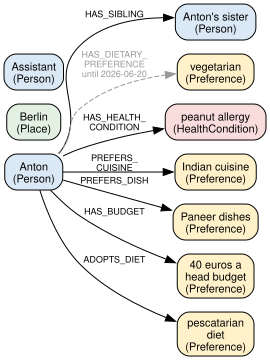

In [22]:
draw(graph)

The remaining messages of session 2 go through the same function.

In [23]:
for message in MESSAGES[4:]:
    LOG[message["label"]] = ingest(graph, message)

table(ingestion_summary([m["label"] for m in MESSAGES[3:]]))

message,entities found,matched to a stored entity,facts added,facts closed
s2.1,"Anton, pescatarian diet, peanut allergy",—,1,1
s2.2,"Assistant, fish",fish → pescatarian diet,1,0
s2.3,"Anton, Kreuzberg",—,1,0
s2.4,"Assistant, Kreuzberg",—,0,0
s2.5,"Anton, Anton's sister Lena, Lena's partner Jonas",Anton's sister Lena → Anton's sister,2,0
s2.6,Assistant,—,0,0
s2.7,"Anton, Lena, shellfish, Jonas, coeliac",Jonas → Lena's partner Jonas,2,0


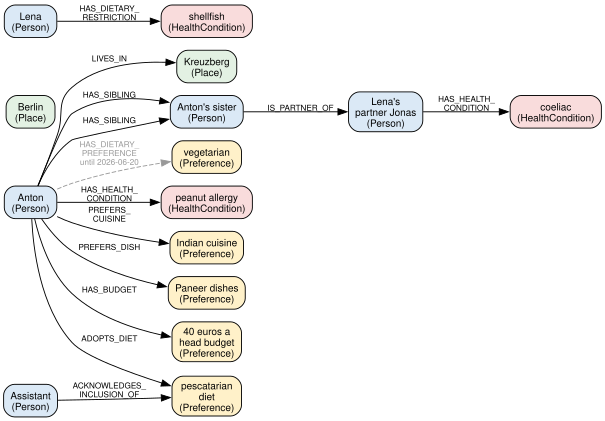

In [24]:
draw(graph)

In [25]:
table(facts_table(graph.facts))

from,relation,to,fact,valid_at,invalid_at,created_at,expired_at
Anton,HAS_SIBLING,Anton's sister,Anton has a sister who is visiting Berlin.,2026-03-14,—,2026-03-14,—
Anton,HAS_DIETARY_PREFERENCE,vegetarian,Anton has been strictly vegetarian for eight years.,2018-03-14,2026-06-20,2026-03-14,2026-07-20
Anton,HAS_HEALTH_CONDITION,peanut allergy,Anton has a severe anaphylactic peanut allergy.,2026-03-14,—,2026-03-14,—
Anton,PREFERS_CUISINE,Indian cuisine,Anton prefers Indian cuisine for his dinner plans.,2026-03-14,—,2026-03-14,—
Anton,PREFERS_DISH,Paneer dishes,Anton specifically prefers paneer dishes when eating Indian cuisine.,2026-03-14,—,2026-03-14,—
Anton,HAS_BUDGET,40 euros a head budget,Anton has a budget of 40 euros a head for his dinner.,2026-03-14,—,2026-03-14,—
Anton,ADOPTS_DIET,pescatarian diet,Anton started following a pescatarian diet about a month ago.,2026-06-20,—,2026-07-20,—
Assistant,ACKNOWLEDGES_INCLUSION_OF,pescatarian diet,The Assistant acknowledges that fish is now included in the dietary requirements.,2026-07-20,—,2026-07-20,—
Anton,LIVES_IN,Kreuzberg,Anton moved to the neighborhood of Kreuzberg in May 2026.,2026-05-01,—,2026-07-20,—
Anton,HAS_SIBLING,Anton's sister,Anton has a sister named Lena.,2026-07-20,—,2026-07-20,—


Thirteen facts: twelve open and one closed. Going down the summary table:

- **s2.2**, the assistant saying *"Noted, fish is in"*, was ingested like any
  other message. Its entity *fish* was judged to be the same thing as the
  stored *pescatarian diet*, which is a stretch, and a fact was stored about
  what the assistant acknowledged. It carries no information the user's own
  message had not already given.
- **s2.3**: *"in May"* became `valid_at = 2026-05-01`.
- **s2.5**: *"my sister Lena"* was matched to the *Anton's sister* node from
  March, and Jonas was added with an edge from her to him.
- **s2.7**: *Jonas* was matched to the stored *Lena's partner Jonas*. **Lena
  was not matched to anything**, so there are now two nodes for the same
  person, and *"Lena cannot eat shellfish"* hangs off the new one, at the top
  of the picture, connected to nothing else. Section 5 looks at why.

### The facts on a timeline

The same facts, drawn by the dates they were true in the world. This is the
view the dates are for.

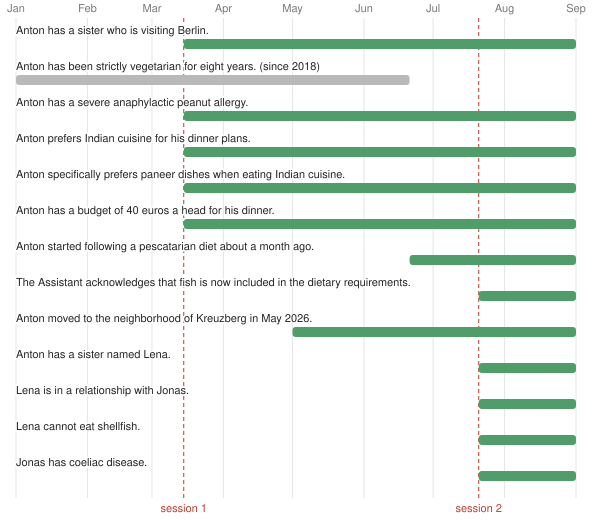

In [26]:
def timeline(facts, start=datetime(2026, 1, 1, tzinfo=timezone.utc), end=TODAY, marks=()):
    """Draw each fact as a bar from valid_at to invalid_at. `marks` are dated vertical lines."""
    row, left, width = 36, 16, 560
    span = (end - start).total_seconds()

    def x(moment):
        return left + width * min(1.0, max(0.0, (moment - start).total_seconds() / span))

    height = row * len(facts) + 52
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{left + width + 24}" height="{height}" '
           f'font-family="Helvetica" font-size="11">',
           '<rect width="100%" height="100%" fill="white"/>']
    for month in range(1, 10):
        tick = datetime(2026, month, 1, tzinfo=timezone.utc)
        out.append(f'<line x1="{x(tick)}" y1="18" x2="{x(tick)}" y2="{height - 22}" stroke="#e5e5e5"/>')
        out.append(f'<text x="{x(tick)}" y="12" text-anchor="middle" fill="#777">{tick:%b}</text>')
    for moment, label in marks:
        out.append(f'<line x1="{x(moment)}" y1="18" x2="{x(moment)}" y2="{height - 22}" '
                   f'stroke="#c0392b" stroke-dasharray="4 3"/>')
        out.append(f'<text x="{x(moment)}" y="{height - 8}" text-anchor="middle" fill="#c0392b">{label}</text>')
    for i, fact in enumerate(facts):
        y = 24 + i * row                     # the sentence on one line, its bar underneath
        begin = fact.valid_at or fact.created_at
        colour = "#b9b9b9" if fact.invalid_at else "#4f9d69"
        since = f"  (since {begin:%Y})" if begin < start else ""
        out.append(f'<text x="{left}" y="{y + 10}" fill="#222" stroke="white" stroke-width="3" '
                   f'paint-order="stroke">{fact.text}{since}</text>')
        out.append(f'<rect x="{x(begin)}" y="{y + 15}" width="{max(3, x(fact.invalid_at or end) - x(begin))}" '
                   f'height="10" rx="3" fill="{colour}"/>')
    out.append("</svg>")
    return SVG("".join(out))


timeline(graph.facts, marks=[(SESSION_DATES["s1"], "session 1"), (SESSION_DATES["s2"], "session 2")])

Green bars are facts the graph holds as true today. Grey bars have ended.
Nothing was deleted: a closed fact stays in the graph as history.

Because every fact has a start and an end, *"what was true in April?"* is a
filter, not a reconstruction:

In [27]:
def true_on(facts, moment):
    return [f for f in facts
            if (f.valid_at is None or f.valid_at <= moment)
            and (f.invalid_at is None or f.invalid_at > moment)]


april = datetime(2026, 4, 15, tzinfo=timezone.utc)
diet_words = ("vegetarian", "pescatarian")
table(pd.DataFrame({
    "true on 15 April": pd.Series([f.text for f in true_on(graph.facts, april)
                                   if any(w in f.text.lower() for w in diet_words)]),
    "true on 1 September": pd.Series([f.text for f in true_on(graph.facts, TODAY)
                                      if any(w in f.text.lower() for w in diet_words)]),
}).fillna(""))

true on 15 April,true on 1 September
Anton has been strictly vegetarian for eight years.,Anton started following a pescatarian diet about a month ago.


One row each, and the right one for each date. A store that overwrites, or one
that only appends, cannot answer the April question.

### Three ways the closing can fail to happen

The date rule in `close_contradicted` is short, and each of its conditions is
a way for a contradiction to be found and then not acted on.

- **The old fact has to be shown to the model.** The candidates are the top 10
  results of a text search for the new fact. On a large graph, a stale fact
  that the search does not surface is never compared.
- **Both facts need a `valid_at`.** If the model left either date empty, none
  of the three conditions is true, and nothing is closed even though the model
  said *contradicted*.
- **The old fact must have started earlier.** If a contradiction arrives out
  of order (*"I was vegetarian until 2019"*, said today), it is the *new* fact
  that gets the end date. That is correct, and it is something a store with
  one timestamp cannot do.

## 4. Reading it back

A new session, in September. The question is searched against the facts with
the same `search` function used in step 4: this mirrors `graphiti.search()`,
which ranks by wording and by meaning and returns the top 10.

Here is every fact in the graph, scored against the question.

In [28]:
question_vector = embed_texts([QUESTION], "question")[0]
print(QUESTION, "\n")

by_wording = rank_by_wording(QUESTION, graph.facts)
returned = search(QUESTION, question_vector, graph.facts)


def position(fact, ranking):
    return ranking.index(fact) + 1 if fact in ranking else None


scores = pd.DataFrame([
    {"fact": f.text,
     "still true": "yes" if f in true_on(graph.facts, TODAY) else "no",
     "cosine": round(float(f.vector @ question_vector), 3),
     "wording rank": position(f, by_wording),
     "final rank": position(f, returned)}
    for f in graph.facts
]).sort_values("cosine", ascending=False).reset_index(drop=True)
scores[["wording rank", "final rank"]] = scores[["wording rank", "final rank"]].astype("Int64")
table(scores)

My sister and her partner are in town tonight. Book the three of us somewhere for dinner — you know what we can and can't eat. 



fact,still true,cosine,wording rank,final rank
Anton has a sister who is visiting Berlin.,yes,0.671,3,1
Anton prefers Indian cuisine for his dinner plans.,yes,0.665,4,3
Anton has a budget of 40 euros a head for his dinner.,yes,0.646,5,5
The Assistant acknowledges that fish is now included in the dietary requirements.,yes,0.639,,6
Lena cannot eat shellfish.,yes,0.636,1,2
Anton specifically prefers paneer dishes when eating Indian cuisine.,yes,0.616,,7
Anton has been strictly vegetarian for eight years.,no,0.608,,8
Anton has a sister named Lena.,yes,0.607,2,4
Anton has a severe anaphylactic peanut allergy.,yes,0.602,,9
Anton started following a pescatarian diet about a month ago.,yes,0.599,,


Nine facts were returned: the five that share a word with the question, plus
those that score at least 0.6 on meaning. Read the bottom of the table against
the top.

- **The closed vegetarian fact was returned** (0.608).
- **The pescatarian fact that replaced it was not** (0.599, and no word in
  common with the question).
- **Jonas's coeliac disease was not returned** either (0.596, no word in
  common).

So the write side did its job, and the read side handed back the old diet
without the new one. Storing an update correctly and delivering it are two
separate problems.

### The 0.6 floor

The meaning half of the search drops every fact that scores under 0.6
(`DEFAULT_MIN_SCORE`). That number is one constant in the library, and what it
does depends entirely on the embedding model. Here is how many facts pass at
different floors, with the model used in this notebook:

In [29]:
all_scores = np.array([float(f.vector @ question_vector) for f in graph.facts])
table(pd.DataFrame([{"floor": floor, "facts that pass": int((all_scores >= floor).sum()),
               "of": len(all_scores)} for floor in (0.5, 0.55, 0.6, 0.65, 0.7)]))

floor,facts that pass,of
0.500,13,13
0.550,11,13
0.600,9,13
0.650,2,13
0.700,0,13


With this embedding model every fact scores between 0.54 and 0.67 against the
question, whether it is relevant or not. A floor of 0.6 cuts through the
middle of that narrow band, and which side a fact lands on is decided by the
third decimal: the vegetarian fact is in at 0.608, the pescatarian fact is out
at 0.599. With another embedding model the same constant might let everything
through, or nothing. It has to be set for the model in use. (The experiments
in the Zep paper used BGE-m3 embeddings.)

### Closed facts come back too

The default search does not look at the dates. A fact that was closed in July
is ranked like any other. Graphiti has filters for this, and they have to be
asked for. Here the filter is `true_on`:

In [30]:
current = search(QUESTION, question_vector, true_on(graph.facts, TODAY))
table(pd.DataFrame({
    "default search": pd.Series([f.text + ("   [ENDED]" if f.invalid_at else "") for f in returned]),
    "current facts only": pd.Series([f.text for f in current]),
}).fillna(""))

default search,current facts only
Anton has a sister who is visiting Berlin.,Anton has a sister who is visiting Berlin.
Lena cannot eat shellfish.,Lena cannot eat shellfish.
Anton prefers Indian cuisine for his dinner plans.,Anton prefers Indian cuisine for his dinner plans.
Anton has a sister named Lena.,Anton has a sister named Lena.
Anton has a budget of 40 euros a head for his dinner.,Anton has a budget of 40 euros a head for his dinner.
The Assistant acknowledges that fish is now included in the dietary requirements.,The Assistant acknowledges that fish is now included in the dietary requirements.
Anton specifically prefers paneer dishes when eating Indian cuisine.,Anton specifically prefers paneer dishes when eating Indian cuisine.
Anton has been strictly vegetarian for eight years. [ENDED],Anton has a severe anaphylactic peanut allergy.
Anton has a severe anaphylactic peanut allergy.,


## 5. What does the graph buy?

So far nothing has needed a graph. Facts with a start and an end date could
sit in a table, and the search above read them as a list of sentences. So what
are the nodes and edges for?

### One node for one real thing

The sister is mentioned three ways: *"my sister"* in March, *"my sister Lena"*
in July, and plain *"Lena"* two messages later. Step 2 is what joins them.
Here is the model call that did it:

In [31]:
match_call = next(c for c in CALLS if c["step"].startswith("2.") and c.get("message") == "s2.5")
prompt = match_call["prompt"]
print(prompt[prompt.index("<CURRENT MESSAGE>"):prompt.index("Each of the above")].strip())
table(pd.DataFrame(match_call["reply"]["entity_resolutions"]))

<CURRENT MESSAGE>
Anton: Yes — my sister Lena is coming back in the autumn, and she's bringing her partner, Jonas.
</CURRENT MESSAGE>

<ENTITIES>
[{"id": 0, "name": "Anton's sister Lena", "entity_type": ["Person"]}]
</ENTITIES>

<EXISTING ENTITIES>
[{"candidate_id": 0, "name": "Anton's sister", "entity_types": ["Person"]}, {"candidate_id": 1, "name": "Anton", "entity_types": ["Person"]}]
</EXISTING ENTITIES>


id,name,duplicate_candidate_id
0,Anton's sister Lena,0


In [32]:
merged = [(label, found_name, stored_name)
          for label, entry in LOG.items()
          for found_name, stored_name in entry["same_as"].items() if found_name != stored_name]
table(pd.DataFrame(merged, columns=["message", "name in the message", "entity in the graph"]))

message,name in the message,entity in the graph
s2.2,fish,pescatarian diet
s2.5,Anton's sister Lena,Anton's sister
s2.7,Jonas,Lena's partner Jonas


The model was shown two stored entities and correctly chose *Anton's sister*.
From then on, facts about *"my sister"* and facts about *"my sister Lena"*
attach to one node. A list of sentences has no place to record that two
phrases mean the same person.

That is two good merges out of three (*fish → pescatarian diet* is doubtful).
But there should be a fourth row: *Lena*, in s2.7. Here is why it is missing.
Before asking the model, step 2 keeps only the stored entities whose **name**
is at least 0.6 similar to the new name:

In [33]:
lena = graph.entities["Lena"]
stored_then = [e for e in graph.entities.values() if e.name not in [f.name for f in LOG["s2.7"]["found"]]
               or e.name in LOG["s2.7"]["same_as"].values() and e is not lena]
table(pd.DataFrame([
    {"stored entity": e.name, "similarity to “Lena”": round(float(e.vector @ lena.vector), 3),
     "offered to the model as a candidate": "yes" if e.vector @ lena.vector >= NODE_DEDUP_COSINE_MIN_SCORE else "no"}
    for e in stored_then if e is not lena
]).sort_values("similarity to “Lena”", ascending=False).reset_index(drop=True))

stored entity,similarity to “Lena”,offered to the model as a candidate
Lena's partner Jonas,0.787,yes
Anton,0.608,yes
Assistant,0.600,no
Anton's sister,0.595,no
Berlin,0.594,no
Kreuzberg,0.574,no
vegetarian,0.561,no
peanut allergy,0.549,no
shellfish,0.549,no
coeliac,0.539,no


*Anton's sister* scored 0.595, so it was never offered to the model as a
candidate for Lena. The model was offered *Lena's partner Jonas* and *Anton*,
and rightly said that neither of them is Lena. A name on its own carries very little meaning for an embedding
to work with: *Lena* is about as close to *Assistant* and *Berlin* as to
*Anton's sister*.

So the graph is only as connected as this step makes it, and this step turns
on the same kind of fixed threshold as the search.

One caveat about how far this carries over. The Zep paper describes a second
source of candidates: a full-text search over entity names and summaries. The
version of the library followed here (0.30) collects candidates by name
similarity only, and this notebook leaves entity summaries out altogether. A
summary of the sister that mentioned *Lena* could have caught this.

### A question that needs a chain

The question says *"my sister and her partner"*. It does not say Lena, Jonas,
shellfish or gluten. To answer it, something has to get from *sister* to
*Jonas*, and from each of them to what they cannot eat.

Three ways of reading the same stored facts (only the ones still true today):

1. **Text search.** The search from section 4, which is what
   `graphiti.search()` does by default.
2. **Text search, then walk.** Take the entities that the text hits start
   from, follow edges outward for up to three steps, and merge the facts found
   on the way into the ranking. This is what Graphiti's search recipes that
   include `bfs` (breadth-first search) do.
3. **Walk from the entities the question names.** Find the stored entities
   whose names share a word with the question, and follow edges outward from
   those only. In Graphiti this is a search with `bfs_origin_node_uuids` set.

In [34]:
def walk(graph, start_names, steps):
    """Facts reached by following edges outward from the given entities, nearest first."""
    frontier, seen, found = set(start_names), set(start_names), []
    for _ in range(steps):
        outgoing = [f for f in graph.facts if f.source in frontier and f not in found]
        found += outgoing
        frontier = {f.target for f in outgoing} - seen
        seen |= frontier
    return found


def entities_named_in(graph, text):
    """The stored entities whose name shares a word with the text."""
    asked = set(words(text))
    return [e.name for e in graph.entities.values() if asked & set(words(e.name))]


current_facts = true_on(graph.facts, TODAY)
current_graph = Graph(graph.entities, current_facts)

# 1. text search
text_hits = search(QUESTION, question_vector, current_facts)

# 2. text search, then walk outward from the entities those hits start from
hit_entities = {f.source for f in text_hits}
walked = walk(current_graph, hit_entities, steps=MAX_SEARCH_DEPTH)
text_and_walk = merge_rankings(rank_by_wording(QUESTION, current_facts),
                               rank_by_meaning(question_vector, current_facts), walked)[:10]

# 3. walk from the entities the question names
named = entities_named_in(current_graph, QUESTION)
chain = walk(current_graph, named, steps=2)

print("entities the text hits start from:", sorted(hit_entities))
print("entities the question names:      ", named)
NEEDED = ("pescatarian", "peanut", "shellfish", "coeliac")
comparison = pd.DataFrame([
    {"fact": f.text,
     "needed": "yes" if any(w in f.text.lower() for w in NEEDED) else "",
     "1. text search": position(f, text_hits),
     "2. text search, then walk": position(f, text_and_walk),
     "3. walk from the question's entities": position(f, chain)}
    for f in current_facts
])
for column in comparison.columns[2:]:
    comparison[column] = comparison[column].astype("Int64")
table(comparison)

entities the text hits start from: ['Anton', 'Assistant', 'Lena']
entities the question names:       ["Anton's sister", "Lena's partner Jonas"]


fact,needed,1. text search,"2. text search, then walk",3. walk from the question's entities
Anton has a sister who is visiting Berlin.,,1,1,
Anton has a severe anaphylactic peanut allergy.,yes,8,6,
Anton prefers Indian cuisine for his dinner plans.,,3,3,
Anton specifically prefers paneer dishes when eating Indian cuisine.,,7,7,
Anton has a budget of 40 euros a head for his dinner.,,5,5,
Anton started following a pescatarian diet about a month ago.,yes,,9,
The Assistant acknowledges that fish is now included in the dietary requirements.,,6,8,
Anton moved to the neighborhood of Kreuzberg in May 2026.,,,10,
Anton has a sister named Lena.,,4,4,
Lena is in a relationship with Jonas.,,,,1


The numbers are positions in each result list; `<NA>` means not returned.
The facts found by the third reading, drawn on the graph:

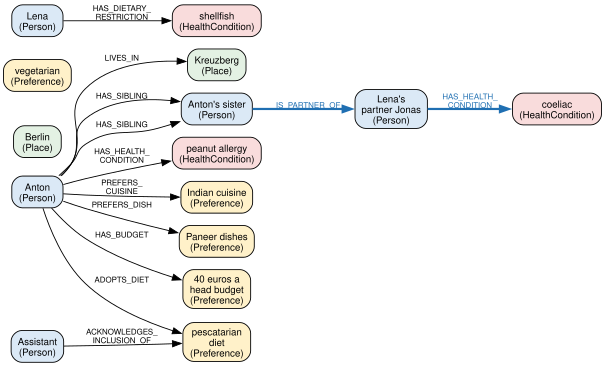

In [35]:
draw(current_graph, highlight=chain)

Take the four needed facts one at a time.

- **Jonas has coeliac disease.** Text search cannot find it: the sentence
  shares no word with the question and scores under the floor. The second
  reading does reach it, three steps out from Anton, but it is merged in behind
  all the nearer facts and falls outside the top 10. **The third reading finds
  it in two steps: sister → Jonas → coeliac.** That path exists only because
  step 2 matched *"my sister Lena"* and *"Jonas"* to nodes that were already
  there.
- **Lena cannot eat shellfish.** Found by text search, because it shares the
  word *eat* with the question. No walk can find it: it sits on the second
  *Lena* node, which is connected to nothing.
- **The pescatarian diet.** Missed by text search, found by the second reading
  one step from Anton.
- **The peanut allergy.** Found by text search.

### So when is the graph useful?

**It is useful when the question names one thing and the answer is a fact
about a different thing that is linked to it**, worded in a way that has
nothing to do with the question. *"My sister's partner"* to *"Jonas has
coeliac disease"* is that case. Similarity search has nothing to hold on to
there, and adding more facts to the store only makes it worse. A walk along
two edges does not depend on wording at all.

It also gave us the duplicate check by node pair in section 3, which is how
the repeated peanut allergy was caught.

**It adds little for facts about the user.** Those are all one step from the
user's node. Listing them needs no graph: a table of facts with a `subject`
column and the same dates would return the same rows. The handling of time in
section 3 does not need a graph either.

**It depends on step 2 being right.** One missed match, by 0.005, and a fact
becomes unreachable by walking.

**And it is not used by default.** The Zep paper describes three search
methods side by side: full-text, cosine similarity and breadth-first search,
the last one for facts that are *"closer in the graph"* to what was found. In
the library, `graphiti.search()` is the first reading only: a text search
over fact sentences. The walk has to be requested through a search recipe,
and the application has to decide where it starts.

## 6. Does it change the answer?

Graphiti formats search results for the model with a fixed template: each fact
with its dates, and one sentence explaining what the dates mean. Here is the
question answered twice: once with the default search from section 4, and once
with the second reading above (current facts only, text search and then a walk).

In [36]:
def context_for(facts):
    """Graphiti's context template (search_results_to_context_string), facts only."""
    listed = [{"fact": f.text, "valid_at": str(f.valid_at), "invalid_at": str(f.invalid_at or "Present")}
              for f in facts]
    return ("These are the most relevant facts and their valid and invalid dates. Facts are considered "
            "valid between their valid_at and invalid_at dates. Facts with an invalid_at date of "
            '"Present" are considered valid.\n<FACTS>\n' + json.dumps(listed, indent=1) + "\n</FACTS>")


def answer(facts, label):
    reply = generate(
        f"What you remember about this user:\n{context_for(facts)}\n\nTheir request: {QUESTION}",
        system=f"You are a booking assistant for {USER}. Today is {TODAY:%d %B %Y}. Be brief and concrete.",
    )
    CALLS.append({"step": "answer", "message": label, "prompt": "", "reply": reply.text,
                  "tokens in": reply.usage_metadata.prompt_token_count,
                  "tokens out": reply.usage_metadata.candidates_token_count})
    return reply.text.strip()


print("1. DEFAULT SEARCH (text only, closed facts included)\n")
print(answer(returned, "default search"))

1. DEFAULT SEARCH (text only, closed facts included)

I will book a table for three for tonight. 

**Dietary requirements:**
*   **Anton:** Severe peanut allergy.
*   **Lena:** No shellfish.
*   **General:** Indian cuisine, budget €40/head, preference for paneer dishes.

I will proceed with these constraints. Shall I confirm once the reservation is made?


In [37]:
tuned_ranking = merge_rankings(rank_by_wording(QUESTION, current_facts),
                               rank_by_meaning(question_vector, current_facts, floor=0.55),
                               chain)
tuned = tuned_ranking[:10]

print("2. TUNED READ (current facts only, floor 0.55, walk from the question's entities)\n")
print(answer(tuned, "tuned read"))

2. TUNED READ (current facts only, floor 0.55, walk from the question's entities)

I will book a table for three for tonight, September 1st. 

I have noted the following requirements:
*   **Cuisine:** Indian (specifically paneer dishes).
*   **Budget:** €40 per person.
*   **Dietary Restrictions:** 
    *   Anton: Severe peanut allergy.
    *   Lena: No shellfish.
    *   Jonas: Coeliac disease (gluten-free).
    *   General: Fish is included in the menu.

I will proceed with the booking now. Would you like me to prioritize a specific area in Berlin?


In [38]:
needed_facts = [f for f in current_facts if any(w in f.text.lower() for w in NEEDED)]
table(pd.DataFrame([
    {"needed fact": f.text,
     "in the default search": "yes" if f in returned else "no",
     "in the tuned read": "yes" if f in tuned else "no",
     "rank in the tuned read": position(f, tuned_ranking)}
    for f in needed_facts
]).astype({"rank in the tuned read": "Int64"}))

needed fact,in the default search,in the tuned read,rank in the tuned read
Anton has a severe anaphylactic peanut allergy.,yes,yes,10
Anton started following a pescatarian diet about a month ago.,no,no,11
Lena cannot eat shellfish.,yes,yes,2
Jonas has coeliac disease.,no,yes,6


**The default search gives an answer that looks complete and is not.** It has
the peanut allergy, Lena's shellfish and the cuisine. It says nothing about
what Anton himself eats, because it was given the closed vegetarian fact and
not the pescatarian one. And it says nothing about gluten, so Jonas would be
booked into a restaurant with no thought for coeliac disease.

**The tuned read fixes the second problem and half of the first.** Jonas's
coeliac disease is now in the answer, brought in by the walk. *"Fish is
included"* is there too, but look at the table: it did not come from the
pescatarian fact, which is still missing. It came from the fact stored about
the assistant's acknowledgement in s2.2. The pescatarian sentence ranks
eleventh of twelve for a question about dinner, and the limit is ten.

Neither answer mentions Kreuzberg, which is in the graph and was not
retrieved.

## 7. What it costs

Model calls for the two sessions, by step.

In [39]:
labels = [m["label"] for m in MESSAGES]
calls = pd.DataFrame([c for c in CALLS if c["message"] in labels])
calls["session"] = calls["message"].str[:2]

by_step = calls.groupby("step").agg(
    calls=("step", "size"), tokens_in=("tokens in", "sum"), tokens_out=("tokens out", "sum"))
by_step.loc["TOTAL"] = by_step.sum()
table(by_step.reset_index())

step,calls,tokens_in,tokens_out
1. find entities,10,"24,118","1,273"
2. match entities,7,"6,818",486
3. extract facts,8,"13,277","1,544"
4. compare with stored facts,11,"7,077",182
TOTAL,36,"51,290","3,485"


In [40]:
embeds = pd.DataFrame(EMBEDS)
per_message = pd.DataFrame({
    "LLM calls": calls.groupby("message").size(),
    "embedding calls": embeds.groupby("message").size(),
}).reindex(labels).fillna(0).astype(int)
per_message.insert(0, "speaker", [m["role"] for m in MESSAGES])
per_message.loc["TOTAL"] = ["", per_message["LLM calls"].sum(), per_message["embedding calls"].sum()]
table(per_message.reset_index())

message,speaker,LLM calls,embedding calls
s1.1,user,2,4
s1.2,assistant,2,1
s1.3,user,6,4
s2.1,user,5,3
s2.2,assistant,4,2
s2.3,user,4,2
s2.4,assistant,2,1
s2.5,user,5,3
s2.6,assistant,1,1
s2.7,user,5,3


**36 model calls and 24 embedding calls for ten short messages.** For
comparison, [Mem0](02-mem0.ipynb) stores the same two sessions with two model
calls, which read about 16,900 tokens. Three things drive the number here.

- **Every message is ingested separately**, with the earlier ones passed along
  as context. Graphiti requires messages to be added in order, one after
  another, because step 4 reads what the previous message wrote.
- **Step 4 is one call per new fact**, so the count grows with how much a
  message says, not with how many messages there are.
- **The assistant's messages are not free.** Four of the ten messages are the
  assistant's. They cost 9 of the 36 calls and produced one fact, which
  nobody needed.

The entity prompt is the largest: about 2,400 tokens each time, most of it
the rules and examples shown in section 1. The whole run reads about 51,000
tokens to store thirteen facts.

## What to take away

The four questions from the top.

**1. Writing: what goes into the graph?** Only what step 1 names as an entity. A fact
needs two entities to exist. Out of the box the entity prompt is written for
named things, and it left out the diet and the allergy; four custom entity
types brought them in. This is the first thing to tune for a personal-memory
use.

**2. Revising: what happens to the old fact?** It gets an end date and stays in the
graph. The model judges *that* two facts conflict; ordinary code decides
*which* one ends and *when*, from the dates. This worked cleanly here, and it
makes *"what was true in April?"* a filter.

**3. The graph: what does it give you over a table of dated facts?** One node per
real thing, a duplicate check between the same two nodes, and a way to reach a
fact through linked entities when its wording has nothing in common with the
question. For facts about the user themselves, and for the handling of time,
a table would do the same.

**4. Cost: what does it cost?** 36 model calls for ten messages.

### What went wrong in this run, and where

| What happened | Step | Cause | What fixes it |
|---|---|---|---|
| Diet and allergy not stored | 1. find entities | the prompt asks for named things | custom entity types (done above) |
| Two nodes for Lena | 2. match entities | name similarity 0.595, under a 0.6 floor | a floor set for the embedding model in use |
| Old diet returned, new diet not | read | same 0.6 floor; closed facts not filtered | a date filter, and the floor again |
| Coeliac fact not returned | read | text search only | a walk from the entities in the question |
| A fact about what the assistant acknowledged | ingestion | every message is ingested | ingesting the user's messages only |

Four of the five are settings, not flaws in the design. That is the main thing
this notebook shows: the idea of dated edges is sound and simple, and nearly
everything that decides whether it works in practice is a threshold or a
prompt that has to be set for the application.

### Things worth trying

- **Lower `NODE_DEDUP_COSINE_MIN_SCORE` to 0.55** and re-run session 2. Does
  *Lena* now merge with *Anton's sister*, and does the walk then reach the
  shellfish fact?
- **Ingest only the user's messages.** How many calls does that save, and is
  anything lost?
- **Say the reversal less directly**: *"grabbed some salmon last night, been
  doing that a lot lately"*. Does step 4 still call it a contradiction?
- **Add a contradiction out of order**: a message saying *"I ate fish until
  2017"*. Which fact gets the end date?